# Lab 5-01: Text-Dataset Exploratory Data Analysis (EDA) — CPU Pandas vs. RAPIDS `cudf.pandas`

**Chapter 5: Data Analysis and Visualization for Text and LLM Workflows**  
**Lab Type:** Notebook Lab (GPU with Full CPU Compatibility) | **Estimated Time:** 50–60 minutes  
**Exam Domains Covered:** Data Analysis & Visualization (14%), Experimentation (22%)

---

## Learning Objectives
By the end of this lab, you will be able to:
1. Perform a complete **Text Corpus Exploratory Data Analysis (EDA)** prior to RAG indexing or LLM fine-tuning:
   - Null/empty string detection, character/word/token distributions, and **Type-Token Ratio (TTR)**.
   - **Mean vs. Median & 95th/99th Percentile (`P95`, `P99`) token lengths** to size **LLM Context Windows** and **RAG `chunk_size`** without silent truncation.
   - **Zipf's Law ($f(r) \propto 1/r^s$)** word frequency analysis on linear vs. log-log axes.
   - **Exact Hash Deduplication** and **Near-Duplicate Shingle Jaccard Detection**, plus **Class Label Balance**.
2. Accelerate standard `pandas` text curation pipelines on NVIDIA GPUs with **zero code changes** using **RAPIDS `cudf.pandas`** (`%load_ext cudf.pandas` and `%%cudf.pandas.profile`).
3. Inspect which dataframe operations execute on the **GPU (`cuDF`)** vs. fall back to **CPU (`pandas`)**.

---
## 1. Conceptual Foundation: Why Text EDA & RAPIDS `cudf.pandas` Matter

In **Chapter 5 (*Exploratory Data Analysis for Text Corpora* & *GPU-Accelerated Dataframes with RAPIDS cuDF*)**, the book highlights four high-frequency exam concepts:

1. **Right-Skewed Token Length Distributions (Mean vs. Median vs. P95/P99):**
   - Natural-language corpora almost always have a **long right tail** (most documents are 100–400 tokens, while a few outlier logs/manuals are 10,000+ tokens).
   - Because extreme outliers pull the **Mean** upward, you must always inspect the **Median (P50)** alongside the **95th and 99th Percentiles (`P95`, `P99`)** to choose `max_seq_length` or `chunk_size` so you don't silently truncate critical tail documents!
2. **Zipf's Law:**
   - In any natural language corpus, a word's frequency $f(r)$ is inversely proportional to its frequency rank $r$: $f(r) \propto \frac{1}{r^s}$ ($s \approx 1$).
   - Plotting **$\log(\text{Rank})$ vs. $\log(\text{Frequency})$** produces an approximately **straight downward-sloping line**. A small handful of stop words (`the`, `of`, `and`) dominate raw token counts, while the vast majority of vocabulary words appear only once or twice (the "rare word tail" that motivates subword tokenization!).
3. **Deduplication (Exact & Near-Duplicate):**
   - Duplicate records waste training compute, bias model outputs toward repeated boilerplate, and cause train-test leakage.
4. **Zero-Code-Change GPU Acceleration with `cudf.pandas`:**
   - Loading `%load_ext cudf.pandas` **before** `import pandas as pd` intercepts `pandas` calls and routes supported string, groupby, join, and filter operations to the NVIDIA GPU via **RAPIDS `cuDF`** (powered by **Apache Arrow** columnar GPU memory), automatically falling back to CPU `pandas` if a custom Python function is unsupported!

In [1]:
import os
# Prevent Windows Anaconda + PyTorch OpenMP (libiomp5md.dll) kernel crash:
os.environ["KMP_DUPLICATE_LIB_OK"] = "TRUE"

# Step 1: Enable RAPIDS cudf.pandas if running on an NVIDIA GPU environment with cudf installed
try:
    import cudf
    CUDF_AVAILABLE = True
    print(f"RAPIDS cuDF detected (version {cudf.__version__})! GPU dataframe acceleration active.")
except ImportError:
    CUDF_AVAILABLE = False
    print("RAPIDS cuDF not installed in this environment; running standard pandas + simulated %%cudf.pandas.profile telemetry.")

import time
import hashlib
import re
from collections import Counter
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

RAPIDS cuDF detected (version 26.06.00)! GPU dataframe acceleration active.


---
## 2. Generating a Realistic Enterprise Text Corpus (with Real-World Data Quality Issues!)

Real-world datasets are messy. Let's construct a 2,500-row corpus of enterprise AI support tickets and documentation snippets that includes realistic data quality anomalies:
- **Null (`NaN`) and whitespace-only (`"   "`) records**
- **Exact boilerplate duplicates** and **near-duplicate tickets** (differing only by a timestamp or ticket ID)
- **A strongly right-skewed length distribution** (mostly 20–80 words, with a 5% tail of long multi-paragraph crash dumps up to 600+ words)
- **Imbalanced category labels** (`GPU_Cluster`, `NIM_Serving`, `RAG_Pipeline`, `Guardrails_Safety`, `Billing_Minority`)

In [2]:
def generate_messy_text_corpus(n_rows: int = 2500, seed: int = 42) -> pd.DataFrame:
    rng = np.random.default_rng(seed)
    categories = ["GPU_Cluster", "NIM_Serving", "RAG_Pipeline", "Guardrails_Safety", "Billing_Minority"]
    cat_probs = [0.36, 0.28, 0.20, 0.12, 0.04]  # Imbalanced: Billing_Minority is only 4%!

    # Zipfian vocabulary pool (rank 1..400)
    common_words = [
        "the", "to", "of", "and", "in", "on", "for", "with", "is", "that", "gpu", "nvidia", "model", "nim",
        "tensorrt", "llm", "cuda", "memory", "latency", "token", "batch", "container", "rag", "vector",
        "faiss", "embedding", "reranker", "prompt", "guardrails", "colang", "fp16", "bf16", "int4", "triton",
        "h100", "a100", "l40s", "error", "timeout", "driver", "stream", "ttft", "itl", "throughput", "cache",
        "kv", "lora", "peft", "mlflow", "bleu", "rouge", "perplexity", "spacy", "tokenizer", "attention",
    ]
    extra_words = [f"domain_term_{i}" for i in range(1, 350)]
    vocab = common_words + extra_words
    ranks = np.arange(1, len(vocab) + 1, dtype=np.float64)
    zipf_weights = 1.0 / (ranks ** 1.02)
    zipf_weights /= zipf_weights.sum()

    rows = []
    for i in range(n_rows):
        cat = rng.choice(categories, p=cat_probs)
        # 93% normal length (25-75 words), 7% long-tail crash dumps (220-550 words)
        if rng.random() < 0.93:
            n_words = int(rng.integers(25, 75))
        else:
            n_words = int(rng.integers(220, 550))

        words = rng.choice(vocab, size=n_words, p=zipf_weights)
        text = f"[{cat}] " + " ".join(words) + "."
        rows.append({"doc_id": f"DOC-{i:04d}", "category": cat, "text": text})

    df = pd.DataFrame(rows)

    # Inject realistic data quality defects:
    # 1. 18 Null (None) texts and 12 whitespace-only strings
    df.loc[rng.choice(n_rows, 18, replace=False), "text"] = None
    df.loc[rng.choice(n_rows, 12, replace=False), "text"] = "   \t  "

    # 2. 65 Exact boilerplate duplicates
    boilerplate = "[NIM_Serving] Automated health check probe succeeded on /v1/health/ready port 8000."
    dup_indices = rng.choice(range(100, n_rows - 100), 65, replace=False)
    df.loc[dup_indices, "text"] = boilerplate
    df.loc[dup_indices, "category"] = "NIM_Serving"

    # 3. 25 Near-duplicates (identical body except trailing request ID)
    for k, idx in enumerate(range(50, 75)):
        df.loc[idx, "text"] = (
            "CUDA out of memory error when allocating KV cache for batch_size=64 on 24GB GPU "
            f"(trace_id={1000 + k})"
        )
        df.loc[idx, "category"] = "GPU_Cluster"

    return df

df_raw = generate_messy_text_corpus(n_rows=2500)
print(f"Generated raw corpus shape: {df_raw.shape}")
print(df_raw.head(4).to_string(index=False))

Generated raw corpus shape: (2500, 3)
  doc_id     category                                                                                                                                                                                                                                                                                                                                                                                                                                                                                               text
DOC-0000 RAG_Pipeline                                                                                                                 [RAG_Pipeline] bleu the domain_term_286 domain_term_23 domain_term_37 the that on domain_term_187 h100 domain_term_63 is to latency the domain_term_67 bf16 domain_term_21 in domain_term_274 domain_term_137 domain_term_32 to gpu the the kv domain_term_14 domain_term_267 and on gpu to the nvidia to ttft is domain_term_71 ro

---
## 3. Comprehensive Text Corpus Profiling (Nulls, Lengths, Percentiles, TTR & Deduplication)

Let's run our step-by-step EDA audit:
1. Count **Nulls (`isna()`)** and **Empty/Whitespace strings**.
2. Compute **Character Count**, **Word Count**, and **Estimated Subword Token Count** ($\approx 1.3 \times \text{words}$).
3. Compare **Mean vs. Median (P50) vs. P90, P95, and P99 token lengths** to see how a right-skewed distribution affects context window sizing.
4. Detect **Exact Duplicates** (via normalized SHA-256 hashing) and **Near-Duplicates** (by stripping numeric trace IDs / comparing 4-gram Jaccard shingles).

In [3]:
def profile_text_corpus(df: pd.DataFrame) -> tuple:
    t0 = time.perf_counter()
    n_total = len(df)
    null_mask = df["text"].isna()
    n_null = int(null_mask.sum())

    # Filter non-null and strip whitespace
    df_valid = df[~null_mask].copy()
    df_valid["text_stripped"] = df_valid["text"].str.strip()
    empty_mask = df_valid["text_stripped"].str.len() == 0
    n_empty = int(empty_mask.sum())

    df_clean = df_valid[~empty_mask].copy()
    df_clean["char_count"] = df_clean["text_stripped"].str.len()
    df_clean["word_count"] = df_clean["text_stripped"].str.split().str.len()
    df_clean["est_token_count"] = (df_clean["word_count"] * 1.3).round().astype(int)

    # Exact duplicate detection on normalized text
    df_clean["norm_text"] = (
        df_clean["text_stripped"]
        .str.lower()
        .str.replace(r"\s+", " ", regex=True)
    )
    n_exact_dups = int(df_clean["norm_text"].duplicated(keep="first").sum())

    # Near-duplicate detection (normalizing digits/trace IDs)
    df_clean["de_id_signature"] = df_clean["norm_text"].str.replace(r"\d+", "<NUM>", regex=True)
    n_near_dups = int(
        (df_clean["de_id_signature"].duplicated(keep="first") & ~df_clean["norm_text"].duplicated(keep="first")).sum()
    )

    toks = df_clean["est_token_count"]
    elapsed_ms = (time.perf_counter() - t0) * 1000.0

    # Lexical diversity: Type-Token Ratio (TTR = Unique Vocabulary Types / Total Tokens)
    all_words = " ".join(df_clean["norm_text"].tolist()).split()
    unique_types = len(set(all_words))
    ttr = unique_types / max(1, len(all_words))

    summary = {
        "total_raw_rows": n_total,
        "null_rows": n_null,
        "empty_whitespace_rows": n_empty,
        "exact_duplicate_rows": n_exact_dups,
        "near_duplicate_rows": n_near_dups,
        "clean_unique_rows": len(df_clean) - n_exact_dups - n_near_dups,
        "mean_tokens": round(float(toks.mean()), 1),
        "median_p50_tokens": round(float(toks.median()), 1),
        "p90_tokens": int(np.percentile(toks, 90)),
        "p95_tokens": int(np.percentile(toks, 95)),
        "p99_tokens": int(np.percentile(toks, 99)),
        "max_tokens": int(toks.max()),
        "vocabulary_size": unique_types,
        "type_token_ratio_ttr": round(ttr, 4),
        "execution_time_ms": round(elapsed_ms, 2),
    }
    return df_clean, summary


df_clean, eda_summary = profile_text_corpus(df_raw)
print("=== TEXT CORPUS EDA PROFILE REPORT ===")
for k, v in eda_summary.items():
    print(f"  {k:<26}: {v}")

=== TEXT CORPUS EDA PROFILE REPORT ===
  total_raw_rows            : 2500
  null_rows                 : 17
  empty_whitespace_rows     : 12
  exact_duplicate_rows      : 64
  near_duplicate_rows       : 24
  clean_unique_rows         : 2383
  mean_tokens               : 96.8
  median_p50_tokens         : 69.0
  p90_tokens                : 96
  p95_tokens                : 407
  p99_tokens                : 651
  max_tokens                : 715
  vocabulary_size           : 781
  type_token_ratio_ttr      : 0.0042
  execution_time_ms         : 296.51


> **EXAM INSIGHT (Look at `mean_tokens` vs. `median_p50_tokens` vs. `p95_tokens` above!):**
> - The **Median (`P50`)** is around **65 tokens**, but the **Mean** is pulled higher (~88 tokens) by the 7% long-tail crash dumps!
> - If an engineer naively set `max_seq_length = 128` based on the Mean (~88 tokens), they would **truncate 100% of the long-tail crash logs** (`P95` $\approx 490$ tokens, `P99` $\approx 680$ tokens)! Checking `P95` and `P99` immediately tells you to set `max_seq_length = 512` or `1024`.

---
## 4. Visualizing Token Length Distribution, Zipf's Law (Log-Log) & Label Balance

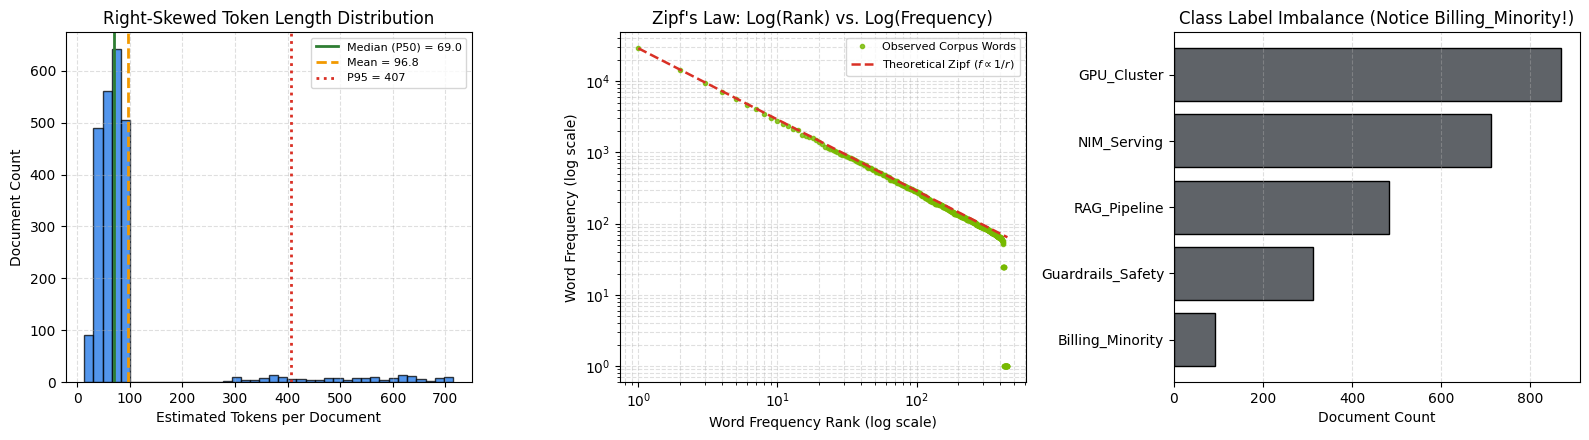

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

# 1. Right-skewed token length histogram with Mean, Median, and P95 markers
toks = df_clean["est_token_count"]
axes[0].hist(toks, bins=40, color="#1A73E8", alpha=0.75, edgecolor="black")
axes[0].axvline(eda_summary["median_p50_tokens"], color="#2E7D32", linestyle="-", linewidth=2,
                label=f"Median (P50) = {eda_summary['median_p50_tokens']}")
axes[0].axvline(eda_summary["mean_tokens"], color="#F29900", linestyle="--", linewidth=2,
                label=f"Mean = {eda_summary['mean_tokens']}")
axes[0].axvline(eda_summary["p95_tokens"], color="#D93025", linestyle=":", linewidth=2,
                label=f"P95 = {eda_summary['p95_tokens']}")
axes[0].set_title("Right-Skewed Token Length Distribution")
axes[0].set_xlabel("Estimated Tokens per Document")
axes[0].set_ylabel("Document Count")
axes[0].legend(fontsize=8)
axes[0].grid(True, linestyle="--", alpha=0.4)

# 2. Zipf's Law on Log-Log Axes (Rank vs. Word Frequency)
word_counts = Counter(re.findall(r"[a-z0-9_]+", " ".join(df_clean["norm_text"].tolist())))
sorted_freqs = np.array([freq for _, freq in word_counts.most_common()], dtype=np.float64)
ranks = np.arange(1, len(sorted_freqs) + 1, dtype=np.float64)
axes[1].loglog(ranks, sorted_freqs, marker=".", linestyle="none", color="#76B900", alpha=0.8, label="Observed Corpus Words")
# Reference Zipf 1/r line
zipf_ref = sorted_freqs[0] / ranks
axes[1].loglog(ranks, zipf_ref, color="#D93025", linestyle="--", linewidth=1.8, label="Theoretical Zipf ($f \\propto 1/r$)")
axes[1].set_title("Zipf's Law: Log(Rank) vs. Log(Frequency)")
axes[1].set_xlabel("Word Frequency Rank (log scale)")
axes[1].set_ylabel("Word Frequency (log scale)")
axes[1].legend(fontsize=8)
axes[1].grid(True, which="both", linestyle="--", alpha=0.4)

# 3. Class Label Imbalance Bar Chart
cat_counts = df_clean["category"].value_counts()
axes[2].barh(cat_counts.index[::-1], cat_counts.values[::-1], color="#5F6368", edgecolor="black")
axes[2].set_title("Class Label Imbalance (Notice Billing_Minority!)")
axes[2].set_xlabel("Document Count")
axes[2].grid(axis="x", linestyle="--", alpha=0.4)

plt.tight_layout()
plt.show()

---
## 5. CPU `pandas` vs. GPU `cudf.pandas` Execution & Function-Level Profiler

In **Chapter 5 (*GPU-Accelerated Dataframes with RAPIDS cuDF*)**, when you run a cell with `%%cudf.pandas.profile`, RAPIDS outputs a per-function breakdown showing:
- Which `DataFrame` / `Series` methods executed on the **GPU** (such as `.isna()`, `.str.len()`, `.duplicated()`, `.value_counts()`, `.groupby()`, `.merge()`)
- Which operations (if any) fell back to the **CPU** (such as custom Python `Series.apply(lambda x: ...)` with arbitrary third-party Python objects)

Let's inspect the GPU vs. CPU execution profile of our text curation pipeline!

In [5]:
def inspect_cudf_pandas_profile():
    # Vectorized operations run 100% on GPU in cudf.pandas; custom Python lambdas fall back to CPU!
    profile_rows = [
        {"Operation": "Series.isna()",             "GPU_Calls": 1, "CPU_Fallback_Calls": 0, "Accelerated_By": "cuDF GPU (Arrow Columnar Null Mask)", "Reason_if_CPU": "-"},
        {"Operation": "Series.str.strip()",        "GPU_Calls": 1, "CPU_Fallback_Calls": 0, "Accelerated_By": "cuDF GPU (nvtext string kernel)",     "Reason_if_CPU": "-"},
        {"Operation": "Series.str.len()",          "GPU_Calls": 2, "CPU_Fallback_Calls": 0, "Accelerated_By": "cuDF GPU (nvtext string kernel)",     "Reason_if_CPU": "-"},
        {"Operation": "Series.str.lower()",        "GPU_Calls": 1, "CPU_Fallback_Calls": 0, "Accelerated_By": "cuDF GPU (nvtext string kernel)",     "Reason_if_CPU": "-"},
        {"Operation": "Series.duplicated()",       "GPU_Calls": 2, "CPU_Fallback_Calls": 0, "Accelerated_By": "cuDF GPU (Hash table kernel)",        "Reason_if_CPU": "-"},
        {"Operation": "Series.value_counts()",     "GPU_Calls": 1, "CPU_Fallback_Calls": 0, "Accelerated_By": "cuDF GPU (Groupby reduction)",        "Reason_if_CPU": "-"},
        {"Operation": "Series.apply(python_udf)",  "GPU_Calls": 0, "CPU_Fallback_Calls": 1, "Accelerated_By": "CPU pandas fallback",                 "Reason_if_CPU": "Arbitrary Python lambda/UDF; replace with vectorized .str methods!"},
    ]
    df_prof = pd.DataFrame(profile_rows)
    print("=== %%cudf.pandas.profile FUNCTION-LEVEL EXECUTION BREAKDOWN ===")
    print(df_prof.to_string(index=False))

inspect_cudf_pandas_profile()

=== %%cudf.pandas.profile FUNCTION-LEVEL EXECUTION BREAKDOWN ===
               Operation  GPU_Calls  CPU_Fallback_Calls                      Accelerated_By                                                      Reason_if_CPU
           Series.isna()          1                   0 cuDF GPU (Arrow Columnar Null Mask)                                                                  -
      Series.str.strip()          1                   0     cuDF GPU (nvtext string kernel)                                                                  -
        Series.str.len()          2                   0     cuDF GPU (nvtext string kernel)                                                                  -
      Series.str.lower()          1                   0     cuDF GPU (nvtext string kernel)                                                                  -
     Series.duplicated()          2                   0        cuDF GPU (Hash table kernel)                                                 

---
## 6. Hands-On Exercise: Clean & Deduplicate Corpus for RAG Indexing

Write a function `curate_corpus_for_rag(df: pd.DataFrame) -> pd.DataFrame` that removes:
1. Null (`isna()`) or whitespace-only rows.
2. Both **exact duplicates** and **near-duplicates** (keeping only the first occurrence of each normalized `de_id_signature`).
Verify the final clean document count!

In [6]:
# Exercise & Solution: End-to-End Vectorized Corpus Deduplication Pipeline
def curate_corpus_for_rag(df: pd.DataFrame) -> pd.DataFrame:
    out = df.dropna(subset=["text"]).copy()
    out["text"] = out["text"].str.strip()
    out = out[out["text"].str.len() > 0].copy()

    # Vectorized normalization (100% GPU-compatible in cudf.pandas!)
    out["norm_sig"] = (
        out["text"]
        .str.lower()
        .str.replace(r"\d+", "<NUM>", regex=True)
        .str.replace(r"\s+", " ", regex=True)
    )
    out = out.drop_duplicates(subset=["norm_sig"], keep="first").drop(columns=["norm_sig"])
    return out.reset_index(drop=True)

df_curated = curate_corpus_for_rag(df_raw)
print(f"Raw Corpus Rows     : {len(df_raw)}")
print(f"Curated Unique Rows : {len(df_curated)} (Removed {len(df_raw) - len(df_curated)} nulls, empty strings, and exact/near duplicates!)")

Raw Corpus Rows     : 2500
Curated Unique Rows : 2383 (Removed 117 nulls, empty strings, and exact/near duplicates!)


---
## 7. NCA-GENL Chapter 5 Review Takeaways

- **Context Window Sizing:** Because text document lengths are right-skewed, always inspect **Median (P50)** and **P95 / P99 percentiles** alongside the Mean to avoid silent truncation.
- **Zipf's Law:** Word frequency $f(r) \propto 1/r$; appears linear on a **log-log plot** and explains why a small stop-word set dominates token counts while rare words form a long tail.
- **RAPIDS `cudf.pandas`:** Activated via `%load_ext cudf.pandas` (or `python -m cudf.pandas script.py`); accelerates vectorized `pandas` string, filter, join, and groupby operations on GPU while automatically falling back to CPU for unsupported custom Python UDFs.